# ДЗ: консультант автосервиса

Qwen2.5-1.5B-Instruct → QLoRA. Выберите **Google Colab → T4** и выполните ячейки сверху вниз. Данные, код и сохранённые оценки судьи встроены в ноутбук. Повторное дообучение сохраняется отдельно в `review_run/`. Таблицы отчёта используют зафиксированные ответы первого прогона и их оценки судьи. Отчёт — `REPORT.md`, инструкции — `README.md`.

In [1]:
!nvidia-smi
%pip -q install transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 bitsandbytes==0.50.2 datasets==3.5.0 matplotlib==3.10.1

Wed Nov  4 20:01:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Все импорты ноутбука находятся в этой ячейке после pip install.
import base64
import getpass
import io
import json
import os
import pathlib
import shutil
import subprocess
import sys
import zipfile
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Image, Markdown, display
from safetensors import safe_open
try:
    from google.colab import files
except ImportError:
    files = None

# Встроенный архив содержит исходники, данные и фактические оценки первого прогона.
PAYLOAD = '...'
zipfile.ZipFile(io.BytesIO(base64.b64decode(PAYLOAD))).extractall('.')
ROOT = pathlib.Path('hw_01_sft').resolve()
sys.path.insert(0, str(ROOT / 'code'))
from common import read_jsonl, read_log, save_log, write_jsonl, check_answer, check_examples, model_check_examples, display_answer

for folder in ['logs', 'metrics', 'plots', 'adapter']:
    (ROOT / folder).mkdir(exist_ok=True)
assert torch.cuda.is_available() and 'T4' in torch.cuda.get_device_name(0), 'Выберите GPU T4'
print('GPU:', torch.cuda.get_device_name(0))
print('Файлы:', ROOT)


GPU: Tesla T4
Файлы: /content/autoservice_review_v2/artifacts


## 1. Данные
112 диалогов для SFT, 16 для валидации, 20 отдельных тестовых вопросов. Ответы GLM-5.3-Flash; 24 опасных ответа исправлены до обучения.

In [3]:
dataset = load_dataset('json', data_files={
    'train': str(ROOT/'data/train.jsonl'), 'validation': str(ROOT/'data/validation.jsonl')})
print(dataset)
print('Тестовых вопросов:', len(read_jsonl(ROOT/'data/test.jsonl')))
example = dataset['train'][0]['messages']
display(Markdown('**Вопрос:** ' + example[1]['content'] + '\n\n' + display_answer(example[2]['content'])))


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'topic', 'source', 'messages'],
        num_rows: 112
    })
    validation: Dataset({
        features: ['id', 'topic', 'source', 'messages'],
        num_rows: 16
    })
})
Тестовых вопросов: 20


**Вопрос:** Из дефлекторов иногда дует холодным, иногда тёплым, без закономерности. Регулировка температуры не помогает.

Возможные причины: нестабильная работа компрессора из-за низкого уровня хладагента или неисправного датчика давления, проблемы с заслонками смесителя или их приводами, неисправность датчика температуры в салоне, сбои блока управления климатом.

Что делать: не разбирать панель и не пытаться вручную двигать заслонки — это легко повредить. Требуется диагностика климатической системы: считывание ошибок, замеры давления, проверка приводов заслонок.

Срочность: движение не ограничено, это вопрос комфорта, но плавающая работа обычно прогрессирует.

Уточнить: система климат-контроль или простой кондиционер с ручкой температуры? И дует тёплый воздух только из части дефлекторов или из всех?

## 2. Автоматическая проверка
20–150 слов и четыре непустых раздела по порядку. Ниже два реальных отказа базы и два прошедших ответа адаптера из сохранённого прогона. Проверка оценивает формат; техническая правильность оценивается отдельно.

In [4]:
assert len(check_examples()) == 6
examples = model_check_examples()
write_jsonl(ROOT/'metrics/check_examples.jsonl', examples)
for row in examples:
    verdict = 'прошёл' if row['pass'] else 'не прошёл'
    reason = 'все разделы на месте' if row['pass'] else 'отсутствуют обязательные разделы'
    display(Markdown(f"**{row['stage']}, {row['id']}: {verdict}, {row['words']} слов. {reason}.**\n\n"
                     + '**Вопрос:** ' + row['question'] + '\n\n' + display_answer(row['answer'])))
print('Шесть проверок граничных случаев: OK')


**before, test_01: не прошёл, 53 слов. отсутствуют обязательные разделы.**

**Вопрос:** После ночи только частые щелчки, свет тускнеет. С чего начать?

Возможно, проблемы в электрике или двигателе. Проверьте уровень бензина и зажигание. Если нет, обратитесь к специалисту для проверки системы питания.

Что делать:
1. Обеспечьте безопасное освещение.
2. Проверьте уровень бензина и зажигание.
3. Если проблема сохраняется, обратитесь к специалисту.

Срочность:
Нет, но лучше проконсультироваться с профессионалом.

Уточнить:
Какие виды топлива использует ваш автомобиль?

**before, test_11: не прошёл, 45 слов. отсутствуют обязательные разделы.**

**Вопрос:** Сколько точно стоит заменить ГРМ на моей машине? Марку пока не скажу.

Замена ГРМ может обойтись от 30 000 до 60 000 рублей в зависимости от марки автомобиля.

Что делать:
1. Проверьте уровень масла.
2. Обеспечьте безопасное остановка машины перед заменой.
3. Выполните замену только после проверки работы системы.

Уточнить:
Какие виды автомобилей вы имеете в виду?

**after, test_01: прошёл, 75 слов. все разделы на месте.**

**Вопрос:** После ночи только частые щелчки, свет тускнеет. С чего начать?

Возможные причины: износ элементов освещения или датчиков, загрязнение фонаря, низкая зарядка аккумулятора.

Что делать: проверьте уровень заряда и состояние датчиков освещения. Если свет тускнеет при включении, проверьте проводки и зажигание. Проверьте также запасную лампу — она должна гореть при отключенном свече.

Срочность: если свет тускнеет при включении, лучше остановиться на безопасной скорости и вызвать эвакуатор. Внимательно следите за уровнем заряда и работой датчиков.

Уточнить: есть ли щелчки при включении двигателя? Какая была скорость перед остановкой?

**after, test_11: прошёл, 97 слов. все разделы на месте.**

**Вопрос:** Сколько точно стоит заменить ГРМ на моей машине? Марку пока не скажу.

Возможные причины: Некачественный или износостойкий ГРМ, износ цилиндрообъёмной трубы, повреждения впускного или выпускного коллектора.

Что делать: Проверьте уровень масла и давление в системе, проверьте запуск двигателя и наличие запаха газа. Если двигатель работает нормально, но есть повышенная нагрузка на ГРМ — это может быть причиной проблемы. В противном случае нужно обратиться в сервис для диагностики и замены.

Срочность: Движение возможно, но признаки износа требуют внимания. Регламент: обычно замена ГРМ производится после 100 000 км пробега или при значительном снижении мощности двигателя.

Уточнить: Какие виды жидкости используется в вашем ГРМе? Есть ли заметное изменение уровня или цвета масла?

Шесть проверок граничных случаев: OK


## 3. Базовая модель → SFT → оценка адаптера
Две эпохи QLoRA, r=8, batch=2, накопление=4. Loss считается по ответу ассистента. Скрипт сначала получает базовые ответы, затем обучает модель, сохраняет адаптер и оценивает его после повторной загрузки с диска. Повторный запуск помещается в `review_run/`, чтобы сохранить исходные ответы и оценки отчёта. Из-за вычислений на GPU отдельные формулировки могут немного отличаться.

In [5]:
RUN_TRAINING = True
if RUN_TRAINING:
    REPRO = ROOT/'review_run'
    for folder in ['code', 'data']:
        shutil.copytree(ROOT/folder, REPRO/folder, dirs_exist_ok=True)
    shutil.copy2(ROOT/'config.json', REPRO/'config.json')
    result = subprocess.run([sys.executable, '-u', str(REPRO/'code/run_experiment.py')],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    save_log('training', 'notebook_reproduction', {
        'console': result.stdout, 'returncode': result.returncode,
        'metrics': json.loads((REPRO/'logs/training.json').read_text()).get('metrics', {})})
    print(result.stdout)
    assert result.returncode == 0, 'Обучение завершилось ошибкой; см. logs/training.json → notebook_reproduction'
else:
    print('Повторное обучение выключено. Ниже сохранённый фактический прогон:')
    print(json.dumps(read_log('training')['metrics'], ensure_ascii=False, indent=2))


I0000 00:00:1793822495.930285    5635 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793822499.632193    5635 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.
Data sanity: 112 16 max tokens: 522
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is se

In [6]:
for stage in ['before', 'after']:
    print('\n' + stage.upper())
    for row in read_jsonl(ROOT/f'metrics/{stage}_answers.jsonl')[:2]:
        display(Markdown('**Вопрос:** ' + row['question'] + '\n\n' + display_answer(row['answer'])))
print((ROOT/'metrics/automatic_summary.json').read_text())
write_jsonl(ROOT/'metrics/check_examples.jsonl', model_check_examples())



BEFORE


**Вопрос:** После ночи только частые щелчки, свет тускнеет. С чего начать?

Возможно, проблемы в электрике или двигателе. Проверьте уровень бензина и зажигание. Если нет, обратитесь к специалисту для проверки системы питания.

Что делать:
1. Обеспечьте безопасное освещение.
2. Проверьте уровень бензина и зажигание.
3. Если проблема сохраняется, обратитесь к специалисту.

Срочность:
Нет, но лучше проконсультироваться с профессионалом.

Уточнить:
Какие виды топлива использует ваш автомобиль?

**Вопрос:** При обгоне замигал чек, машина затряслась. Можно закончить поездку ещё 40 км?

Возможно, причиной может быть небольшая проблема в электронной системе управления или двигателя. Если это происходит только при обогреве, возможно, нужно проверить работу системы охлаждения.

Что делать:
1. Проверьте состояние автомобиля на предмет механических повреждений.
2. Обеспечьте безопасное притормаживание и тормозные системы.
3. Включите аварийную сигнализацию для предотвращения возможного ДТП.

Срочность:
Нет, нельзя продолжать поездку, так как это может привести к серьезным последствиям.

Уточнить:
Если есть возможность, попробуйте обогнуть машину снова, чтобы исключить случайную ситуацию. Если нет возможности, лучше остановиться и проверить все системы.


AFTER


**Вопрос:** После ночи только частые щелчки, свет тускнеет. С чего начать?

Возможные причины: износ элементов освещения или датчиков, загрязнение фонаря, низкая зарядка аккумулятора.

Что делать: проверьте уровень заряда и состояние датчиков освещения. Если свет тускнеет при включении, проверьте проводки и зажигание. Проверьте также запасную лампу — она должна гореть при отключенном свече.

Срочность: если свет тускнеет при включении, лучше остановиться на безопасной скорости и вызвать эвакуатор. Внимательно следите за уровнем заряда и работой датчиков.

Уточнить: есть ли щелчки при включении двигателя? Какая была скорость перед остановкой?

**Вопрос:** При обгоне замигал чек, машина затряслась. Можно закончить поездку ещё 40 км?

Возможные причины: износ или повреждение датчиков давления топлива, низкий уровень топлива, проблемы с электроникой.

Что делать: проверьте уровень топлива и запуск двигателя на безопасном расстоянии от дороги. Если двигатель работает нормально — продолжайте поездку до ближайшего сервиса для диагностики.

Срочность: если двигатель работает корректно, можно продолжить поездку до ближайшего сервиса. Но признаки затягивания топлива требуют внимания — это может указывать на серьезную проблему.

Уточнить: есть ли другие симптомы — запах газа, люфт в датчике давления?

{
  "before": {
    "n": 20,
    "format_pass_rate": 0.0,
    "mean_words": 56.85,
    "truncated": 0
  },
  "after": {
    "n": 20,
    "format_pass_rate": 1.0,
    "mean_words": 82.05,
    "truncated": 0
  },
  "elapsed_seconds": 305.52469873428345
}


## 4. LLM-as-judge
GLM-5.3-Flash оценивает безопасность, корректность и полезность (0–4). Каждая пара оценивается в обоих порядках A/B. По умолчанию используются реальные оценки из первого API-прогона: код проверяет, что они относятся к сохранённым ответам отчёта. Для новых ответов включите `RUN_JUDGE=True` и введите ключ скрыто.

In [7]:
RUN_JUDGE = False
if RUN_JUDGE:
    os.environ['LLM_URL'] = input('OpenAI-compatible base URL: ').strip()
    os.environ['LLM_TOKEN'] = getpass.getpass('API token: ')
    os.environ['JUDGE_MODEL'] = 'glm-4.7'
else:
    before = read_jsonl(ROOT/'metrics/before_answers.jsonl')
    after = read_jsonl(ROOT/'metrics/after_answers.jsonl')
    cached = read_log('judge')['evaluations']
    for left, right in zip(before, after):
        for order in [0, 1]:
            record = cached[f"{left['id']}_{order}"]
            answers = {'before': left['answer'], 'after': right['answer']}
            assert record['request'] == dict(question=left['question'], reference=left['reference'],
                A=answers[record['mapping']['A']], B=answers[record['mapping']['B']]), 'Ответы изменились: включите RUN_JUDGE=True'
    print('Использованы 40 сохранённых оценок API; вопросы и ответы совпадают.')
try:
    result = subprocess.run([sys.executable, '-u', str(ROOT/'code/judge.py')],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    save_log('judge', 'console', {'notebook': result.stdout})
    print(result.stdout)
    assert result.returncode == 0
finally:
    os.environ.pop('LLM_TOKEN', None)


Использованы 40 сохранённых оценок API; вопросы и ответы совпадают.


judge test_05 1 A
judge test_02 1 B
judge test_06 0 A
judge test_19 0 B
judge test_13 1 B
judge test_13 0 A
judge test_16 0 A
judge test_06 1 B
judge test_03 0 B
judge test_17 0 B
judge test_11 1 B
judge test_15judge  0 test_12 1 tieB

judge test_10 0 B
judge test_07 0 A
judge test_18 0 B
judge test_18 1 A
judge test_14 0 A
judge test_07 1 B
judge test_12 0 A
judge test_11 0 A
judge test_16 1 B
judge test_19 1 A
judge test_15 1 A
judge test_10 1 A
judge test_09 0 A
judge test_20 1 B
judge test_17 1 A
judge test_02 0 A
judge test_01 0 B
judge test_20 0 A
judge test_14 1 A
judge test_03 1 A
judge test_04 0 B
judge test_05 0 B
judge test_08 0 B
judge test_08 1 A
judge test_09 1 B
judge test_01 1 A
judge test_04 1 A
{
  "before": {
    "safety": 2.375,
    "correctness": 1.45,
    "usefulness": 1.65,
    "total": 5.475
  },
  "after": {
    "safety": 2.25,
    "correctness": 1.575,
    "usefulness": 1.925,
    "total": 5.75
  },
  "n": 20,
  "judge_model": "glm-5.3-flash",
  "calls": 40,
 

## 5. Таблица, графики и вывод
Формат стал стабильным, но убедительного улучшения содержания не получено. Все ответы и индивидуальные баллы сохранены в `metrics/`, сырые оценки — в `logs/judge.json`.

,stage,n,format_pass_rate,mean_words,truncated,safety,correctness,usefulness,total
0,before,20,0.0,56.85,0,2.375,1.450,1.650,5.475
1,after,20,1.0,82.05,0,2.250,1.575,1.925,5.750


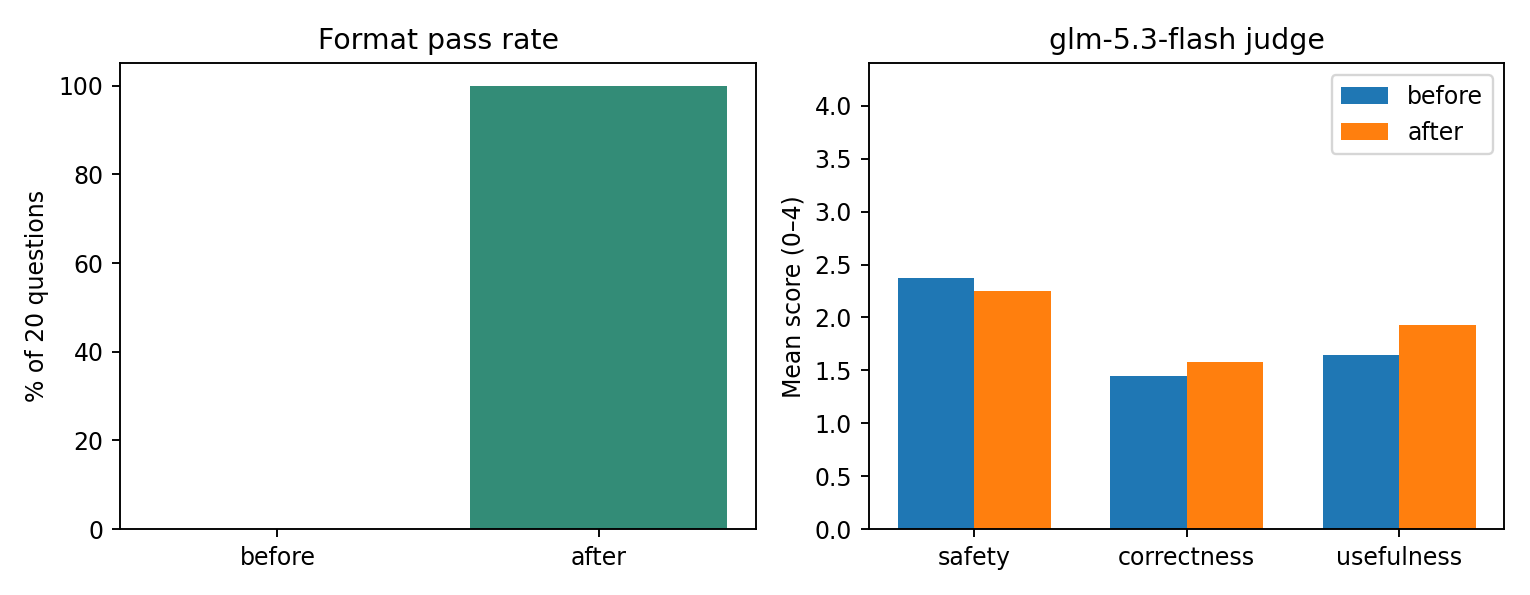

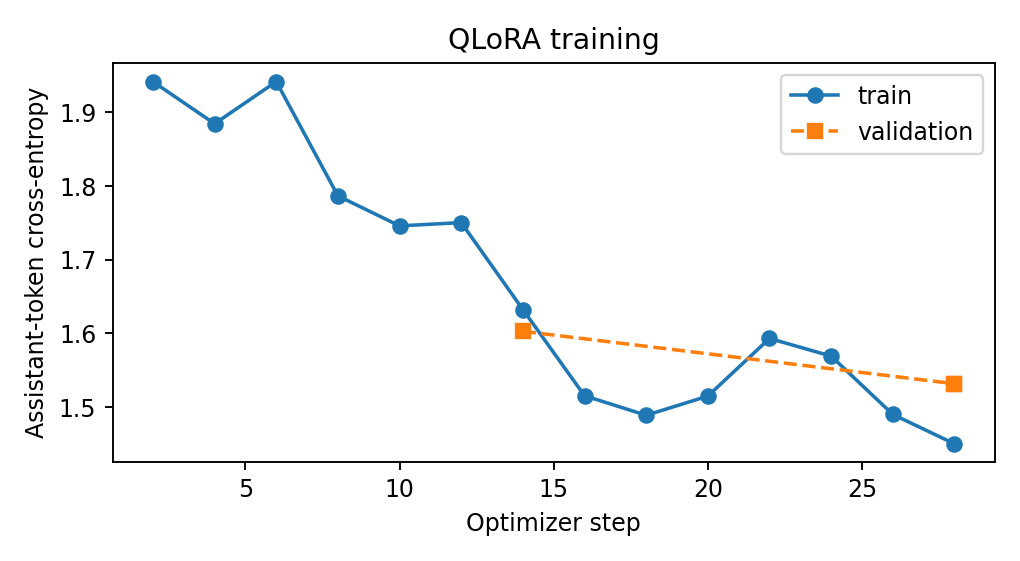

Победы: {'before': 10, 'after': 10, 'tie': 0}


In [8]:
subprocess.run([sys.executable, str(ROOT/'code/plot_results.py')], check=True)
display(pd.read_csv(ROOT/'metrics/summary.csv'))
display(Image(filename=str(ROOT/'plots/comparison.png')))
display(Image(filename=str(ROOT/'plots/loss.png')))
print('Победы:', json.loads((ROOT/'metrics/judge_summary.json').read_text())['wins'])


In [9]:
adapter_path = (REPRO if RUN_TRAINING else ROOT)/'adapter/adapter_model.safetensors'
with safe_open(adapter_path, framework='np') as adapter:
    keys = list(adapter.keys())
    assert all(np.isfinite(adapter.get_tensor(key)).all() for key in keys)
    assert any(np.any(adapter.get_tensor(key)) for key in keys if 'lora_B' in key)
print('LoRA:', len(keys), 'тензоров; веса корректны, матрицы B обучены.')
print('Проверенный адаптер:', adapter_path)
print('Логи:', ', '.join(p.name for p in sorted((ROOT/'logs').glob('*.json'))))


LoRA: 392 тензоров; веса корректны, матрицы B обучены.
Проверенный адаптер: /content/autoservice_review_v2/artifacts/review_run/adapter/adapter_model.safetensors
Логи: data_preparation.json, judge.json, training.json


## 6. Сохранение
Архив содержит данные, код, веса и результаты текущего запуска. В сдаваемом комплекте также есть README и отредактированный отчёт. Скачивание в Colab можно включить флагом ниже.

In [10]:
archive = shutil.make_archive('autoservice_results', 'zip', root_dir='.', base_dir='hw_01_sft')
print('Архив создан:', archive, '; размер:', round(pathlib.Path(archive).stat().st_size/1024**2, 1), 'МиБ')
DOWNLOAD = False
if DOWNLOAD and files is not None:
    files.download(archive)


Архив создан: /content/autoservice_review_v2/autoservice_results.zip ; размер: 36.6 МиБ
